In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from lib import neurons, input_gen, driver, utils

In [2]:
hyper = neurons.HyperConfig1(nd=750, ns=80, n=1, b=4.55, bk=6.00, beta=17.526507)
hyperD = neurons.HyperDynConfig1_SynapticBound(b=4.55, bk=6.00, beta=17.526507, reset_from=3., reset_to=3.)
neuron = neurons.Neuron_Decay_Int_SynapticBound(hyper)
xs_gen = input_gen.Sparse_Binomial(nd=hyper.nd, ns=hyper.ns, fA=0.15, mu=4, n_burst=4, key=jax.random.PRNGKey(42))
# xs_gen = input_gen.Normal(nd=hyper.nd, ns=hyper.ns)

my_driver = driver.Driver1_bScan(
    neuron=neuron,
    xs_generator=xs_gen,
    rng=jax.random.PRNGKey(333),
    hyperD=hyperD,
    initial_state=None,
    resample_every=1000,
    n_tested_patterns=1000,
)

In [ ]:
my_driver.run(
    n_init_steps=8000,
    n_steps_phase1=30000,
    n_steps_phase2=20000,
    n_steps_phase3=10000,
    test_every_phase3=50,
    bs=jnp.array([4.55]),
)

(0.0, 1000.0)

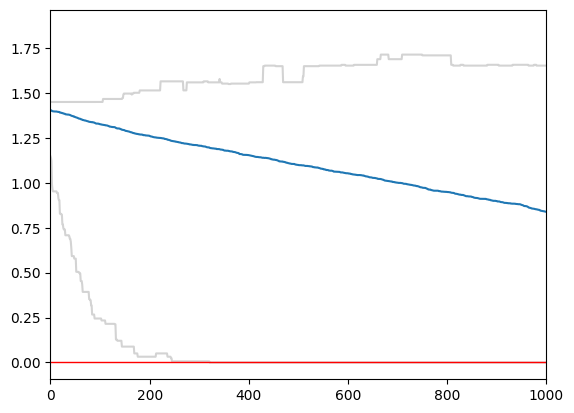

In [6]:
mean = np.mean(my_driver.transient_record, axis=-1)
lower = np.percentile(my_driver.transient_record, 1, axis=-1)
upper = np.percentile(my_driver.transient_record, 99, axis=-1)

steady_upper = np.percentile(my_driver.steady_record, 99, axis=-1)
steady_upper = np.mean(steady_upper, axis=0)

plt.plot(upper, color='lightgrey')
plt.plot(lower, color='lightgrey')
plt.plot(mean)
plt.hlines(steady_upper, 0, 30000, colors='red', linestyles='-', linewidth=1)
plt.xlim(0, 1000)

In [5]:
tmp_xs = xs_gen.generate(jax.random.PRNGKey(123), 1000)